In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import json
import time

import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score, GridSearchCV
from sklearn.metrics import classification_report, recall_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,make_scorer,balanced_accuracy_score, f1_score
import matplotlib.pyplot as plt

data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
refrence_dir = data_dir + '/CHCH_v6_reference/'
reference_mask_dir = refrence_dir + 'processed{}/'
model_save_dir = refrence_dir + 'models/'

In [24]:
infile = refrence_dir + 'peaks_training_df.csv'
peaks_df = pd.read_csv(infile, index_col=[0]) 
print('  <--- ' + infile)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/peaks_training_df.csv


In [25]:
## Filtering

peaks_df = peaks_df.dropna() # removes NaNs (e.g. no temperature data, so bad classification)

# Exclude case study dates from training dataset                           
# eval_dates = [
#     20210518,
#     20210605,
#     ]

peaks_df_eval = peaks_df[peaks_df['date'].isin(eval_dates)]
peaks_df = peaks_df[~peaks_df['date'].isin(eval_dates)]

# Removing peaks with unknown and undetermined reference mask classification
peaks_df = peaks_df[peaks_df['unan_target'] == 0]
peaks_df = peaks_df[peaks_df['undet_target'] == 0]

peaks_df = peaks_df.reset_index(drop=True)

peaks_df['target'] = peaks_df[['wlwc_target','slwc_target','mpc_target', 'ic_target']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slwc_target','mpc_target', 'ic_target'], ordered=True)
peaks_df['target_int']= peaks_df['target'].astype(cat_type).cat.codes  

# Defining groups for the different training datasets        
groups = peaks_df['date'].astype('str').str[:-2]

In [22]:
# np.unique(peaks_df.date)
eval_dates = []
for i in range(15):
    eval_dates.append( np.unique(peaks_df.date)[np.random.randint(0,len(np.unique(peaks_df.date)))-1])

In [23]:
eval_dates

[20211117,
 20210904,
 20211028,
 20210529,
 20211110,
 20211129,
 20210605,
 20210808,
 20210519,
 20210704,
 20211110,
 20210707,
 20210618,
 20211102,
 20210514]

In [26]:
peaks_df_eval = peaks_df_eval[peaks_df_eval['unan_target'] == 0]
peaks_df_eval = peaks_df_eval[peaks_df_eval['undet_target'] == 0]
peaks_df_eval = peaks_df_eval.reset_index(drop=True)
peaks_df_eval['target'] = peaks_df_eval[['wlwc_target','slwc_target','mpc_target', 'ic_target']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slwc_target','mpc_target', 'ic_target'], ordered=True)
peaks_df_eval['target_int']= peaks_df_eval['target'].astype(cat_type).cat.codes  


In [27]:
peaks_df

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target,target,target_int
0,20210515,65,20,0.000027,1.373274,0.000014,0.000027,1.025,1,0,3.064716,1,0,0,0,0,0,0,wlwc_target,0
1,20210515,67,20,0.000167,2.111095,0.000084,0.000166,1.025,1,0,3.010916,1,0,0,0,0,0,0,wlwc_target,0
2,20210515,68,19,0.000308,1.774225,0.000155,0.000308,0.975,1,0,3.326631,1,0,0,0,0,0,0,wlwc_target,0
3,20210515,69,20,0.000290,1.246414,0.000145,0.000289,1.025,1,0,2.961364,1,0,0,0,0,0,0,wlwc_target,0
4,20210515,70,20,0.000113,1.418176,0.000057,0.000112,1.025,1,0,2.938228,1,0,0,0,0,0,0,wlwc_target,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34017,20220120,283,62,0.000199,1.804206,0.000099,0.000199,3.125,1,0,-4.375582,0,1,1,0,0,0,0,slwc_target,1
34018,20220120,286,228,0.000026,3.522913,0.000013,0.000026,11.425,1,0,-54.901438,0,0,0,0,1,0,0,ic_target,3
34019,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,-0.646539,0,0,1,1,0,0,0,mpc_target,2
34020,20220121,36,52,0.000105,1.742200,0.000052,0.000105,2.625,1,0,-0.414722,0,1,1,0,0,0,0,slwc_target,1


In [38]:
print('WLWC Occurrence:', peaks_df.wlwc_target.mean())
print('SLWC Occurrence:', peaks_df.slwc_target.mean())
print('MPC Occurrence:', peaks_df.mpc_target.mean())
print('IC Occurrence:', peaks_df.ic_target.mean())

WLWC Occurrence: 0.5425490577035166
SLWC Occurrence: 0.2142995919953371
MPC Occurrence: 0.06201023249789522
IC Occurrence: 0.18107635515834467


In [28]:
print('WLWC Occurrence:', peaks_df.wlwc_target.mean())
print('SLWC Occurrence:', peaks_df.slwc_target.mean())
print('MPC Occurrence:', peaks_df.mpc_target.mean())
print('IC Occurrence:', peaks_df.ic_target.mean())

WLWC Occurrence: 0.5669272823467169
SLWC Occurrence: 0.23531832343777556
MPC Occurrence: 0.023484803950385044
IC Occurrence: 0.17426959026512256


In [29]:
print('WLWC Occurrence:', peaks_df_eval.wlwc_target.mean())
print('SLWC Occurrence:', peaks_df_eval.slwc_target.mean())
print('MPC Occurrence:', peaks_df_eval.mpc_target.mean())
print('IC Occurrence:', peaks_df_eval.ic_target.mean())

WLWC Occurrence: 0.36810466760961813
SLWC Occurrence: 0.37482319660537483
MPC Occurrence: 0.030056577086280057
IC Occurrence: 0.22701555869872703


In [30]:
## Select input and target variables for model training
input_vars = [
    'peak_magnitude', 
    'peak_width',
    'peak_width_height',
    'peak_prominence',
    'peak_alt',
    'num_peaks',
    'peak_order',
    'peak_temp',
    ]

input = peaks_df[input_vars]                 


### Binary classification - target WLWC

In [62]:
# Selecting target for binary classification
target_vars = 'wlwc_target'

target = peaks_df[target_vars]    
sgkf = StratifiedGroupKFold(n_splits=3)

cv = sgkf
model = xgb.XGBClassifier(objective='binary:logistic',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)
model.fit(input, target)
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='all'))
print()
scores_recall = cross_val_score(model, input, target, cv=cv, scoring='recall', groups=groups)

print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
print()

for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
    print('CV fold', idx)
    print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
    print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
    print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

    model.fit(input.iloc[train], target[train])
    Y_pred = model.predict(input.iloc[test])
    print(idx, classification_report(target[test], Y_pred))

    print(confusion_matrix(target[test], Y_pred,normalize='all'))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     16039
           1       1.00      1.00      1.00     19822

    accuracy                           1.00     35861
   macro avg       1.00      1.00      1.00     35861
weighted avg       1.00      1.00      1.00     35861

[[0.44725468 0.        ]
 [0.         0.55274532]]

[0.99878123 1.         0.99821429] 0.999, 0.001

CV fold 0
Train dataset class ratio = 0.522
Test dataset class ratio = 0.627
Train/Test dataset size = 25396/10465
0               precision    recall  f1-score   support

           0       1.00      1.00      1.00      3901
           1       1.00      1.00      1.00      6564

    accuracy                           1.00     10465
   macro avg       1.00      1.00      1.00     10465
weighted avg       1.00      1.00      1.00     10465

[[0.37152413 0.00124224]
 [0.00076445 0.62646918]]
CV fold 1
Train dataset class ratio = 0.554
Test dataset class ratio = 0.550


### Binary classification - target SLWC

In [29]:
# Selecting target for binary classification
target_vars = 'slwc_target'

target = peaks_df[target_vars]    
sgkf = StratifiedGroupKFold(n_splits=3)

cv = sgkf
model = xgb.XGBClassifier(objective='binary:logistic',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)
model.fit(input, target)
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='all'))
print()
scores_recall = cross_val_score(model, input, target, cv=cv, scoring='recall', groups=groups)

print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
print()

for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
    print('CV fold', idx)
    print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
    print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
    print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

    model.fit(input.iloc[train], target[train])
    Y_pred = model.predict(input.iloc[test])
    print(idx, classification_report(target[test], Y_pred))

    print(confusion_matrix(target[test], Y_pred,normalize='all'))

              precision    recall  f1-score   support

           0       0.99      0.95      0.97     28878
           1       0.85      0.97      0.90      7889

    accuracy                           0.96     36767
   macro avg       0.92      0.96      0.94     36767
weighted avg       0.96      0.96      0.96     36767

[[0.74738216 0.03805043]
 [0.00677238 0.20779503]]

[0.91547708 0.85303514 0.90929122] 0.893, 0.028

CV fold 0
Train dataset class ratio = 0.217
Test dataset class ratio = 0.211
Train/Test dataset size = 24130/12637
0               precision    recall  f1-score   support

           0       0.98      0.92      0.95      9975
           1       0.76      0.92      0.83      2662

    accuracy                           0.92     12637
   macro avg       0.87      0.92      0.89     12637
weighted avg       0.93      0.92      0.92     12637

[[0.72746696 0.06188178]
 [0.01780486 0.1928464 ]]
CV fold 1
Train dataset class ratio = 0.219
Test dataset class ratio = 0.206


### Binary classification - target SLCC

In [31]:
# Selecting target for binary classification
target_vars = 'slcc_target'

target = peaks_df[target_vars]    
sgkf = StratifiedGroupKFold(n_splits=3)

cv = sgkf
model = xgb.XGBClassifier(objective='binary:logistic',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)
model.fit(input, target)
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='all'))
print()
scores_recall = cross_val_score(model, input, target, cv=cv, scoring='recall', groups=groups)

print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
print()

for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
    print('CV fold', idx)
    print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
    print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
    print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

    model.fit(input.iloc[train], target[train])
    Y_pred = model.predict(input.iloc[test])
    print(idx, classification_report(target[test], Y_pred))

    print(confusion_matrix(target[test], Y_pred,normalize='all'))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99     26725
           1       0.96      0.98      0.97     10042

    accuracy                           0.98     36767
   macro avg       0.97      0.98      0.98     36767
weighted avg       0.98      0.98      0.98     36767

[[0.71433623 0.01253842]
 [0.00590203 0.26722333]]

[0.94938165 0.94398093 0.94764724] 0.947, 0.002

CV fold 0
Train dataset class ratio = 0.272
Test dataset class ratio = 0.275
Train/Test dataset size = 24130/12637
0               precision    recall  f1-score   support

           0       0.98      0.97      0.97      9160
           1       0.92      0.95      0.93      3477

    accuracy                           0.96     12637
   macro avg       0.95      0.96      0.95     12637
weighted avg       0.96      0.96      0.96     12637

[[0.70064097 0.02421461]
 [0.01392736 0.26121706]]
CV fold 1
Train dataset class ratio = 0.270
Test dataset class ratio = 0.280


### Multiclass classification: WLWC, SLWC, MPC and IC

0.9728704955616954
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19288
           1       0.91      0.99      0.95      8006
           2       0.99      0.33      0.50       799
           3       0.97      0.95      0.96      5929

    accuracy                           0.97     34022
   macro avg       0.97      0.82      0.85     34022
weighted avg       0.97      0.97      0.97     34022

[[1.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 9.91131651e-01 2.49812641e-04 8.61853610e-03]
 [0.00000000e+00 5.48185232e-01 3.34167710e-01 1.17647059e-01]
 [0.00000000e+00 5.36346770e-02 3.37325013e-04 9.46027998e-01]]

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1041
           1       0.85      0.98      0.91      1060
           2       0.00      0.00      0.00        85
           3       0.96      0.82      0.88       642

    accuracy        

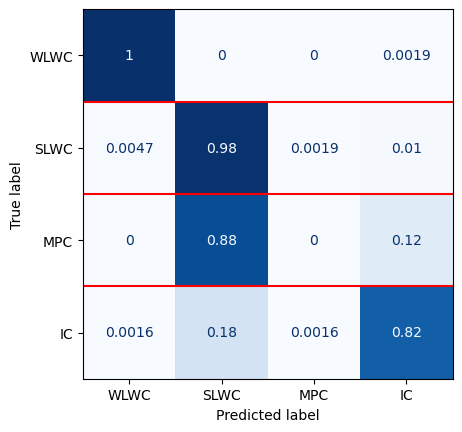

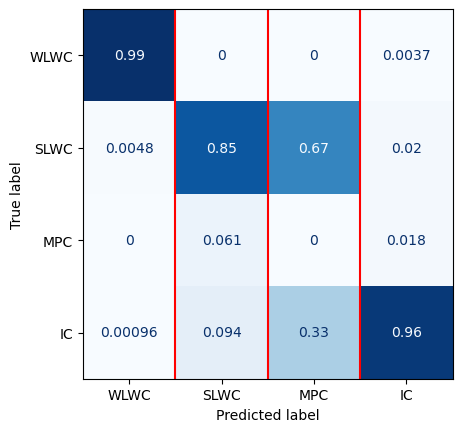

In [31]:
target =  peaks_df['target_int'] 

sgkf = StratifiedGroupKFold(n_splits=3)
cv = sgkf

model = xgb.XGBClassifier(objective='multi:softprob',
                    booster='gbtree', n_jobs=-1,
                    use_label_encoder=False,verbosity=0)

# params_multi = {'gamma': 0, 'learning_rate': 0.3, 'max_depth': 9, 'reg_lambda': 10.0}

# model.set_params(**params_multi)


model.fit(input, target)

print(accuracy_score(target, model.predict(input)))
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='true'))
print()


input_eval = peaks_df_eval[input_vars]
target_eval =  peaks_df_eval['target_int'] 
print(classification_report(target_eval, model.predict(input_eval)))

class_names = ['WLWC','SLWC','MPC', 'IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

# scores_recall = cross_val_score(model, input, target, cv=cv, groups=groups)
# print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
# print()

# for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
#     print('CV fold', idx)
#     print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
#     print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
#     print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

#     model.fit(input.iloc[train], target[train])
#     Y_pred = model.predict(input.iloc[test])
#     print(idx, classification_report(target[test], Y_pred))



Starting grid search
Fitting 3 folds for each of 60 candidates, totalling 180 fits
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.706, test=0.700) total time=   1.2s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.704, test=0.699) total time=   1.3s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.713, test=0.718) total time=   1.4s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.720, test=0.716) total time=   1.7s
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.722, test=0.713) total time=   1.7s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.721, test=0.715) total time=   2.2s
[CV 2/3] END gamma=0, learning_rate=0.02, max_depth=3;, score=(train=0.715, test=0.712) total time=   1.1s
[CV 1/3] END gamma=0, learning_rate=0.02, max_depth=3;, score=(train=0.715, test=0.717) total time=   1.6s
[CV 3/3] END gamma=0, learning_rate=0.02, max_depth=3;, score

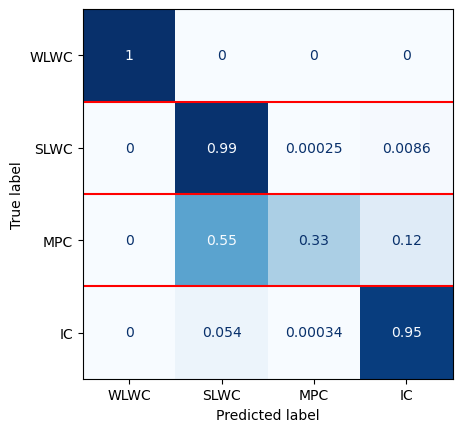

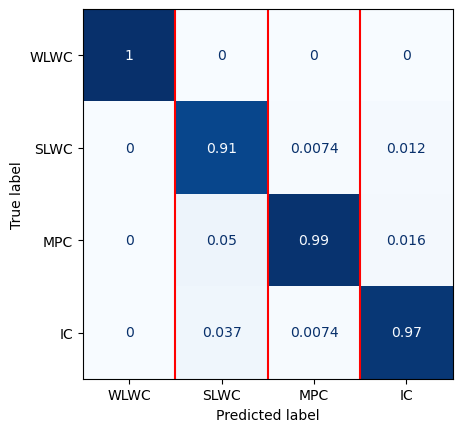

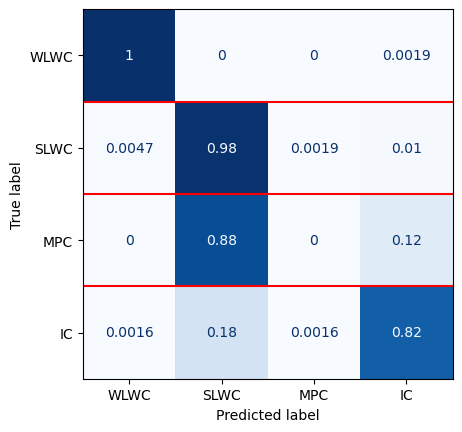

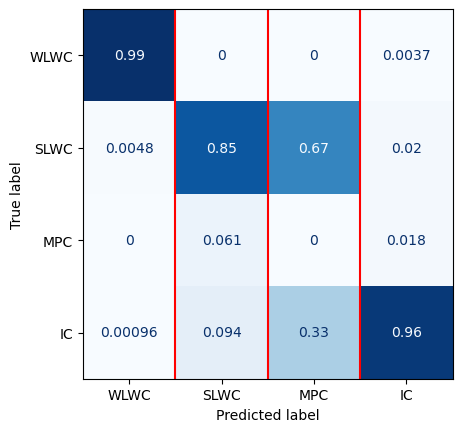

In [32]:
#### Hyperparameter search with GridCV

target =  peaks_df['target_int'] 

sgkf = StratifiedGroupKFold(n_splits=3)
cv = sgkf

model = xgb.XGBClassifier(objective='multi:softprob',
                    booster='gbtree', n_jobs=-1,
                    use_label_encoder=False,verbosity=0)

hyperparameter_space = {
                        'max_depth':[3,6,9], 
                        'learning_rate':[0.01,0.02,0.1,0.3,0.5],
                        'gamma':[0,1,3,6],
                        # 'reg_lambda':[0,1.0,3.0,10.0],
                        # 'scale_pos_weight':[1,3,5]
                        }

gs = GridSearchCV(model, param_grid=hyperparameter_space,verbose=4,scoring='balanced_accuracy',
                n_jobs=-1, cv=cv, return_train_score=True)

print('Starting grid search')
start_time = time.time()
gs.fit(input,target,groups=groups)
print(gs.best_params_)
print(gs.best_score_)
best_model = gs.best_estimator_
print("--- %s seconds ---" % (time.time() - start_time))


# model.fit(input, target)

# best_model = model

# print(accuracy_score(target, best_model.predict(input)))
print(classification_report(target, best_model.predict(input)))
# print(confusion_matrix(target, model.predict(input),normalize='true'))
# print()

# scores_recall = cross_val_score(model, input, target, cv=cv, groups=groups)
# print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
# print()

class_names = ['WLWC','SLWC','MPC', 'IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

print('Evaluation period:')

## Evaluation of case study days
input_eval = peaks_df_eval[input_vars]
target_eval =  peaks_df_eval['target_int'] 
print(classification_report(target_eval, best_model.predict(input_eval)))

disp_true = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')


In [34]:
# balanced_accuracy_score(target, best_model.predict(input))
# f1_score(target, best_model.predict(input), average='weighted')
recall_score(target, best_model.predict(input), average='weighted')


0.9728704955616954

In [33]:
best_model.save_model(model_save_dir+'model_001.json') 

In [187]:
## Get hyperparams for model

json.loads(best_model.get_booster().save_config())

{'learner': {'generic_param': {'device': 'cpu',
   'fail_on_invalid_gpu_id': '0',
   'n_jobs': '-1',
   'nthread': '-1',
   'random_state': '0',
   'seed': '0',
   'seed_per_iteration': '0',
   'validate_parameters': '1'},
  'gradient_booster': {'gbtree_model_param': {'num_parallel_tree': '1',
    'num_trees': '400'},
   'gbtree_train_param': {'process_type': 'default',
    'tree_method': 'auto',
    'updater': 'grow_quantile_histmaker',
    'updater_seq': 'grow_quantile_histmaker'},
   'name': 'gbtree',
   'specified_updater': False,
   'tree_train_param': {'alpha': '0',
    'cache_opt': '1',
    'colsample_bylevel': '1',
    'colsample_bynode': '1',
    'colsample_bytree': '1',
    'eta': '0.300000012',
    'gamma': '0',
    'grow_policy': 'depthwise',
    'interaction_constraints': '',
    'lambda': '0',
    'learning_rate': '0.300000012',
    'max_bin': '256',
    'max_cat_threshold': '64',
    'max_cat_to_onehot': '4',
    'max_delta_step': '0',
    'max_depth': '9',
    'max_leav

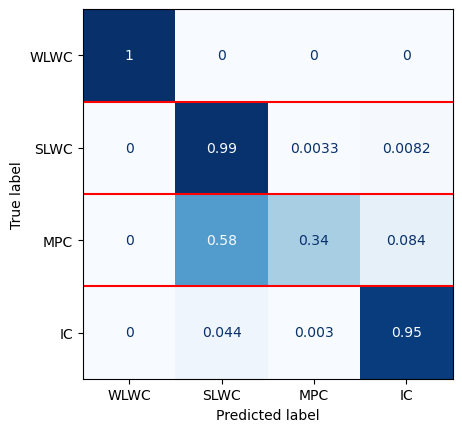

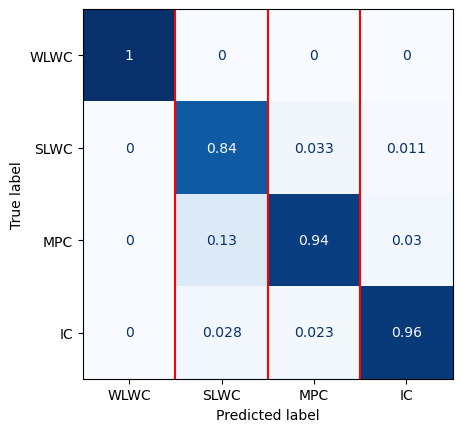

In [91]:
## Code to create confusion matrices:

class_names = ['WLWC','SLWC','MPC', 'IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

### Multiclass Classification WLWC, SLCC, IC

In [36]:
peaks_df['target'] = peaks_df[['wlwc_target','slcc_target', 'ic_target']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slcc_target', 'ic_target'], ordered=True)
peaks_df['target_int']= peaks_df['target'].astype(cat_type).cat.codes  

In [37]:
peaks_df

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target,target,target_int
0,20210515,65,20,0.000027,1.373274,0.000014,0.000027,1.025,1,0,3.064716,1,0,0,0,0,0,0,wlwc_target,0
1,20210515,67,20,0.000167,2.111095,0.000084,0.000166,1.025,1,0,3.010916,1,0,0,0,0,0,0,wlwc_target,0
2,20210515,68,19,0.000308,1.774225,0.000155,0.000308,0.975,1,0,3.326631,1,0,0,0,0,0,0,wlwc_target,0
3,20210515,69,20,0.000290,1.246414,0.000145,0.000289,1.025,1,0,2.961364,1,0,0,0,0,0,0,wlwc_target,0
4,20210515,70,20,0.000113,1.418176,0.000057,0.000112,1.025,1,0,2.938228,1,0,0,0,0,0,0,wlwc_target,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34017,20220120,283,62,0.000199,1.804206,0.000099,0.000199,3.125,1,0,-4.375582,0,1,1,0,0,0,0,slcc_target,1
34018,20220120,286,228,0.000026,3.522913,0.000013,0.000026,11.425,1,0,-54.901438,0,0,0,0,1,0,0,ic_target,2
34019,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,-0.646539,0,0,1,1,0,0,0,slcc_target,1
34020,20220121,36,52,0.000105,1.742200,0.000052,0.000105,2.625,1,0,-0.414722,0,1,1,0,0,0,0,slcc_target,1


In [38]:
peaks_df_eval = peaks_df_eval[peaks_df_eval['unan_target'] == 0]
peaks_df_eval = peaks_df_eval[peaks_df_eval['undet_target'] == 0]
peaks_df_eval = peaks_df_eval.reset_index(drop=True)
peaks_df_eval['target'] = peaks_df_eval[['wlwc_target','slcc_target', 'ic_target']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slcc_target', 'ic_target'], ordered=True)
peaks_df_eval['target_int']= peaks_df_eval['target'].astype(cat_type).cat.codes  


In [39]:
input_vars = [
    'peak_magnitude', 
    'peak_width',
    'peak_width_height',
    'peak_prominence',
    'peak_alt',
    'num_peaks',
    'peak_order',
    'peak_temp',
    ]

input = peaks_df[input_vars]         

In [6]:
peaks_df

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target,target,target_int
0,20210514,43,202,0.000025,5.021346,0.000013,0.000025,10.125,1,0,-53.570575,0,0,0,0,1,0,0,ic_target,2
1,20210514,44,202,0.000022,5.433444,0.000011,0.000023,10.125,1,0,-53.569078,0,0,0,0,1,0,0,ic_target,2
2,20210514,50,195,0.000020,18.462372,0.000010,0.000020,9.775,1,0,-52.376248,0,0,0,0,1,0,0,ic_target,2
3,20210514,51,192,0.000023,16.217988,0.000012,0.000023,9.625,1,0,-51.669931,0,0,0,0,1,0,0,ic_target,2
4,20210514,52,192,0.000020,1.588991,0.000020,0.000001,9.625,2,0,-51.700269,0,0,0,0,1,0,0,ic_target,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31968,20220120,282,62,0.000220,1.962705,0.000110,0.000220,3.125,1,0,-4.408565,0,1,1,0,0,0,0,slcc_target,1
31969,20220120,283,62,0.000199,1.804206,0.000099,0.000199,3.125,1,0,-4.375582,0,1,1,0,0,0,0,slcc_target,1
31970,20220120,286,228,0.000026,3.522913,0.000013,0.000026,11.425,1,0,-54.901438,0,0,0,0,1,0,0,ic_target,2
31971,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,-0.646539,0,1,1,0,0,0,0,slcc_target,1


In [40]:
print('WLWC Occurrence:', peaks_df.wlwc_target.mean())
print('SLCC Occurrence:', peaks_df.slcc_target.mean())
print('IC Occurrence:', peaks_df.ic_target.mean())

WLWC Occurrence: 0.5669272823467169
SLCC Occurrence: 0.2588031273881606
IC Occurrence: 0.17426959026512256


Starting grid search
Fitting 3 folds for each of 60 candidates, totalling 180 fits
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.924, test=0.939) total time=   0.8s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.944, test=0.949) total time=   0.9s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.939, test=0.909) total time=   1.0s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.952, test=0.947) total time=   1.5s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.956, test=0.930) total time=   1.9s
[CV 1/3] END gamma=0, learning_rate=0.02, max_depth=3;, score=(train=0.944, test=0.949) total time=   1.0s
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.952, test=0.953) total time=   2.0s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=9;, score=(train=0.967, test=0.933) total time=   2.4s
[CV 2/3] END gamma=0, learning_rate=0.02, max_depth=3;, score

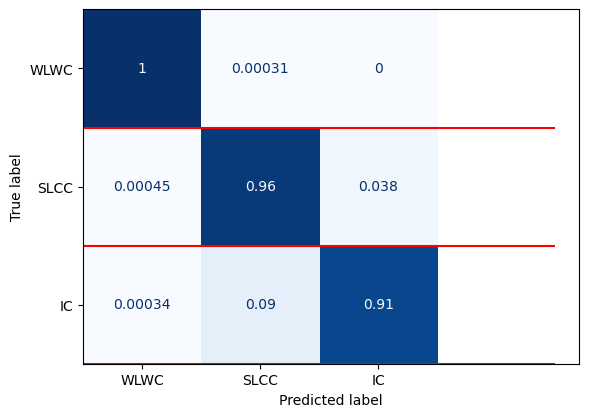

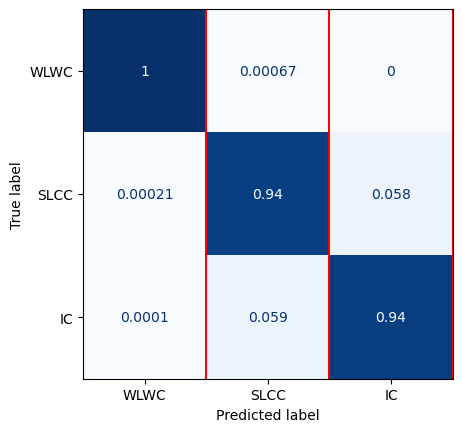

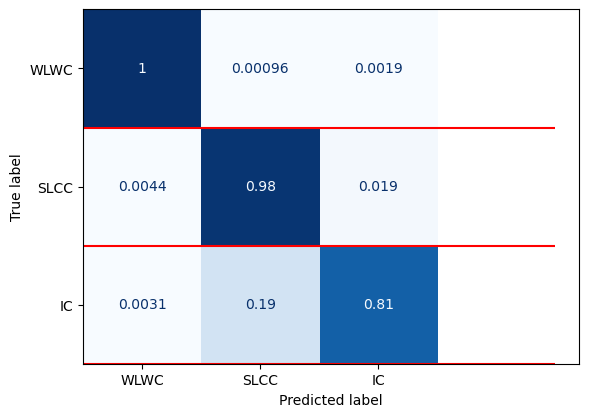

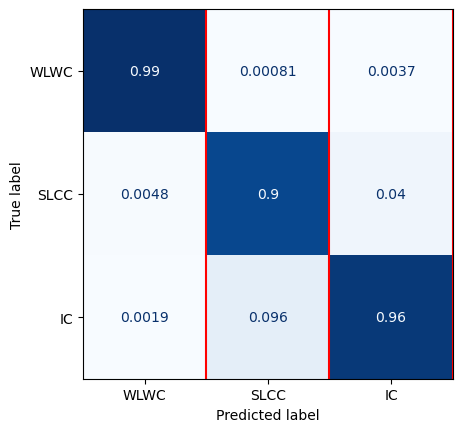

In [41]:
#### Hyperparameter search with GridCV

target =  peaks_df['target_int'] 

sgkf = StratifiedGroupKFold(n_splits=3)
cv = sgkf

model = xgb.XGBClassifier(objective='multi:softprob',
                    booster='gbtree', n_jobs=-1,
                    use_label_encoder=False,verbosity=0)

hyperparameter_space = {
                        'max_depth':[3,6,9], 
                        'learning_rate':[0.01,0.02,0.1,0.3,0.5],
                        'gamma':[0,1,3,6],
                        # 'reg_lambda':[0,1.0,3.0,10.0],
                        # 'scale_pos_weight':[1,3,5]
                        }

gs = GridSearchCV(model, param_grid=hyperparameter_space,verbose=4,scoring='balanced_accuracy',
                n_jobs=-1, cv=cv, return_train_score=True)

print('Starting grid search')
start_time = time.time()
gs.fit(input,target,groups=groups)
print(gs.best_params_)
print(gs.best_score_)
best_model = gs.best_estimator_
print("--- %s seconds ---" % (time.time() - start_time))


# model.fit(input, target)

# best_model = model

# print(accuracy_score(target, best_model.predict(input)))
print(classification_report(target, best_model.predict(input)))
# print(confusion_matrix(target, model.predict(input),normalize='true'))
# print()

# scores_recall = cross_val_score(model, input, target, cv=cv, groups=groups)
# print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
# print()

class_names = ['WLWC','SLCC','IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

print('Evaluation period:')

## Evaluation of case study days
input_eval = peaks_df_eval[input_vars]
target_eval =  peaks_df_eval['target_int'] 
print(classification_report(target_eval, best_model.predict(input_eval)))

disp_true = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')


In [42]:
best_model.save_model(model_save_dir+'model_002.json') 

### Multiclass WLWC, SLWC or neither

In [43]:
peaks_df['neither'] = peaks_df['ic_target'] | peaks_df['mpc_target'] # selects IC and MPC (i.e. neither WLWC or SLWC)

peaks_df['target'] = peaks_df[['wlwc_target','slwc_target', 'neither']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slwc_target', 'neither'], ordered=True)
peaks_df['target_int']= peaks_df['target'].astype(cat_type).cat.codes  


In [44]:
peaks_df_eval['neither'] = peaks_df_eval['ic_target'] | peaks_df_eval['mpc_target'] # selects IC and MPC (i.e. neither WLWC or SLWC)

peaks_df_eval['target'] = peaks_df_eval[['wlwc_target','slwc_target', 'neither']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slwc_target', 'neither'], ordered=True)
peaks_df_eval['target_int']= peaks_df_eval['target'].astype(cat_type).cat.codes  


In [45]:
input_vars = [
    'peak_magnitude', 
    'peak_width',
    'peak_width_height',
    'peak_prominence',
    'peak_alt',
    'num_peaks',
    'peak_order',
    'peak_temp',
    ]

input = peaks_df[input_vars]         

In [46]:
peaks_df

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,...,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target,target,target_int,neither
0,20210515,65,20,0.000027,1.373274,0.000014,0.000027,1.025,1,0,...,1,0,0,0,0,0,0,wlwc_target,0,0
1,20210515,67,20,0.000167,2.111095,0.000084,0.000166,1.025,1,0,...,1,0,0,0,0,0,0,wlwc_target,0,0
2,20210515,68,19,0.000308,1.774225,0.000155,0.000308,0.975,1,0,...,1,0,0,0,0,0,0,wlwc_target,0,0
3,20210515,69,20,0.000290,1.246414,0.000145,0.000289,1.025,1,0,...,1,0,0,0,0,0,0,wlwc_target,0,0
4,20210515,70,20,0.000113,1.418176,0.000057,0.000112,1.025,1,0,...,1,0,0,0,0,0,0,wlwc_target,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34017,20220120,283,62,0.000199,1.804206,0.000099,0.000199,3.125,1,0,...,0,1,1,0,0,0,0,slwc_target,1,0
34018,20220120,286,228,0.000026,3.522913,0.000013,0.000026,11.425,1,0,...,0,0,0,0,1,0,0,neither,2,1
34019,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,...,0,0,1,1,0,0,0,neither,2,1
34020,20220121,36,52,0.000105,1.742200,0.000052,0.000105,2.625,1,0,...,0,1,1,0,0,0,0,slwc_target,1,0


In [47]:
print('WLWC Occurrence:', peaks_df.wlwc_target.mean())
print('SLWC Occurrence:', peaks_df.slwc_target.mean())
print('Neither Occurrence:', peaks_df.neither.mean())

WLWC Occurrence: 0.5669272823467169
SLWC Occurrence: 0.23531832343777556
Neither Occurrence: 0.1977543942155076


In [9]:
peaks_df.wlwc_target.sum()+peaks_df.slwc_target.sum()+peaks_df.neither.sum()

31971

Starting grid search
Fitting 3 folds for each of 60 candidates, totalling 180 fits
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.909, test=0.914) total time=   0.8s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.914, test=0.900) total time=   0.9s
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=3;, score=(train=0.927, test=0.926) total time=   1.2s
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.937, test=0.927) total time=   1.5s
[CV 1/3] END gamma=0, learning_rate=0.02, max_depth=3;, score=(train=0.927, test=0.928) total time=   0.8s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.934, test=0.923) total time=   1.5s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=6;, score=(train=0.934, test=0.929) total time=   1.7s
[CV 2/3] END gamma=0, learning_rate=0.02, max_depth=3;, score=(train=0.925, test=0.918) total time=   0.7s
[CV 3/3] END gamma=0, learning_rate=0.02, max_depth=3;, score

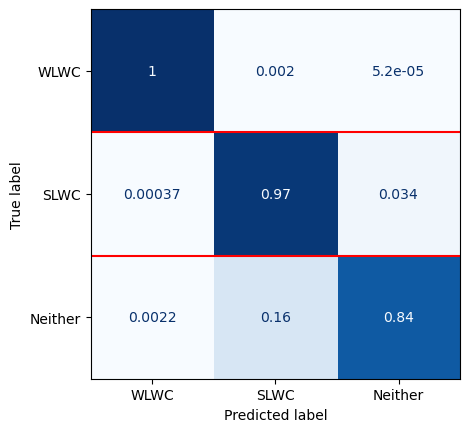

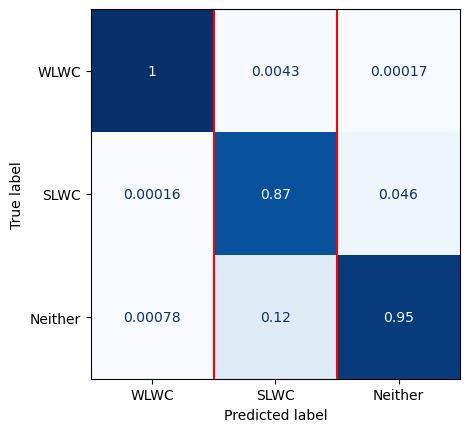

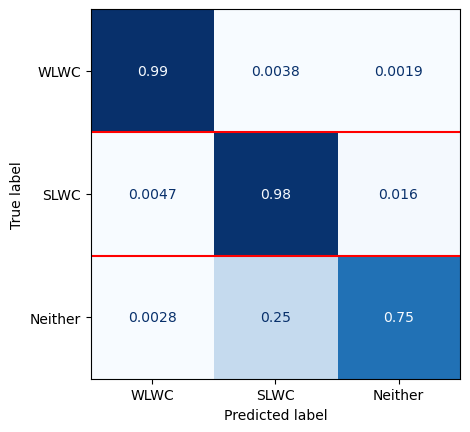

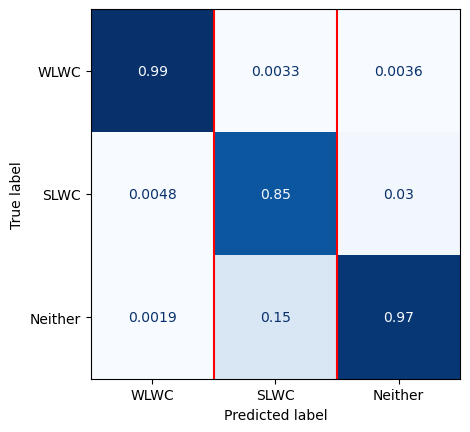

In [48]:
#### Hyperparameter search with GridCV

target =  peaks_df['target_int'] 

sgkf = StratifiedGroupKFold(n_splits=3)
cv = sgkf

model = xgb.XGBClassifier(objective='multi:softprob',
                    booster='gbtree', n_jobs=-1,
                    use_label_encoder=False,verbosity=0)

hyperparameter_space = {
                        'max_depth':[3,6,9], 
                        'learning_rate':[0.01,0.02,0.1,0.3,0.5],
                        'gamma':[0,1,3,6],
                        # 'reg_lambda':[0,1.0,3.0,10.0],
                        # 'scale_pos_weight':[1,3,5]
                        }

gs = GridSearchCV(model, param_grid=hyperparameter_space,verbose=4,scoring='balanced_accuracy',
                n_jobs=-1, cv=cv, return_train_score=True)

print('Starting grid search')
start_time = time.time()
gs.fit(input,target,groups=groups)
print(gs.best_params_)
print(gs.best_score_)
best_model = gs.best_estimator_
print("--- %s seconds ---" % (time.time() - start_time))


# model.fit(input, target)

# best_model = model

# print(accuracy_score(target, best_model.predict(input)))
print(classification_report(target, best_model.predict(input)))
# print(confusion_matrix(target, model.predict(input),normalize='true'))
# print()

# scores_recall = cross_val_score(model, input, target, cv=cv, groups=groups)
# print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
# print()

class_names = ['WLWC','SLWC','Neither']

disp_true = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5], -0.5,2.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5], -0.5,2.5, colors='red')

print('Evaluation period:')

## Evaluation of case study days
input_eval = peaks_df_eval[input_vars]
target_eval =  peaks_df_eval['target_int'] 
print(classification_report(target_eval, best_model.predict(input_eval)))

disp_true = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5], -0.5,2.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5], -0.5,2.5, colors='red')


In [49]:
best_model.save_model(model_save_dir+'model_003.json') 